In [1]:
import pandas as pd
from sqlalchemy import create_engine
import pymysql
from sklearn.preprocessing import MinMaxScaler
import numpy as np
from dotenv import load_dotenv
import os

load_dotenv() # betölti a .env fájlt

db_host = os.getenv("DB_HOST")
db_user = os.getenv("DB_USER")
db_password = os.getenv("DB_PASSWORD")
db_name = os.getenv("DB_NAME")

engine = create_engine( f"mysql+pymysql://{db_user}:{db_password}@{db_host}/{db_name}")

query = """
SELECT 
    valid_time,
    temp_c,
    rh,
    wind_speed,
    wind_dir,
    sp,
    tp
FROM era5_adatok_fix
ORDER BY valid_time
"""

df = pd.read_sql(query, engine, parse_dates=["valid_time"])
df = df.sort_values("valid_time").reset_index(drop=True)
df["valid_time_num"] = df["valid_time"].astype("int64") // 10**9


features = [
    "valid_time_num",
    "temp_c",
    "rh",
    "wind_speed",
    "wind_dir",
    "sp",
    "tp"
]

target = "temp_c"

# input_window = 48
# output_horizon = 6
input_window = 120
output_horizon = 24

scaler = MinMaxScaler()
df[features + [target]] = scaler.fit_transform(df[features + [target]])

df = df.replace([np.inf, -np.inf], np.nan)
df = df.ffill().bfill()

def create_windowed_dataset(df, features, target, input_window, output_horizon):
    X, y = [], []
    data = df[features + [target]].values
    for i in range(len(data) - input_window - output_horizon):
        X.append(data[i:i+input_window, :len(features)])
        y.append(data[i+input_window:i+input_window+output_horizon, -1])
    return np.array(X), np.array(y)

X, y = create_windowed_dataset(df, features, target, input_window, output_horizon)

# split = int(len(X) * 0.8)
split = int(len(X) * 0.9997752)
X_train, X_test = X[:split], X[split:]
y_train, y_test = y[:split], y[split:]

In [2]:
#TCN
import tensorflow as tf
from tensorflow.keras import layers, models

gpus = tf.config.experimental.list_physical_devices('GPU')
if gpus:
    try:
        for gpu in gpus:
            tf.config.experimental.set_memory_growth(gpu, True)
        print("GPU memory growth enabled")
    except RuntimeError as e:
        print(e)


input_shape = (input_window, len(features))

inputs = layers.Input(shape=input_shape)
x = layers.Permute((2, 1))(inputs)  # (batch, features, time)
x = layers.Conv1D(64, kernel_size=3, padding="causal", activation="relu")(x)
x = layers.Conv1D(64, kernel_size=3, padding="causal", activation="relu")(x)
x = layers.GlobalAveragePooling1D()(x)
outputs = layers.Dense(output_horizon)(x)

tcn_model = models.Model(inputs, outputs)
tcn_model.compile(optimizer="adam", loss="mse", metrics=["mae"])

history = tcn_model.fit(
    X_train, y_train,
    validation_split=0.1,
    epochs=15,
    batch_size=64
)


2026-02-13 15:12:23.907365: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


GPU memory growth enabled


I0000 00:00:1770995564.392411  186110 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:10.0, compute capability: 7.5
2026-02-13 15:12:50.677819: W external/local_xla/xla/tsl/framework/cpu_allocator_impl.cc:84] Allocation of 2281564320 exceeds 10% of free system memory.
2026-02-13 15:12:54.221706: W external/local_xla/xla/tsl/framework/cpu_allocator_impl.cc:84] Allocation of 2281564320 exceeds 10% of free system memory.


Epoch 1/15


2026-02-13 15:12:58.585203: I external/local_xla/xla/service/service.cc:163] XLA service 0x70bb80006de0 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
2026-02-13 15:12:58.585239: I external/local_xla/xla/service/service.cc:171]   StreamExecutor device (0): Tesla T4, Compute Capability 7.5
2026-02-13 15:12:58.821257: I tensorflow/compiler/mlir/tensorflow/utils/dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
2026-02-13 15:12:59.316164: I external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:473] Loaded cuDNN version 91900


   62/10610 ━━━━━━━━━━━━━━━━━━━━ 26s 3ms/step - loss: 0.1182 - mae: 0.2657

I0000 00:00:1770995583.550197  186184 device_compiler.h:196] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


10610/10610 ━━━━━━━━━━━━━━━━━━━━ 39s 3ms/step - loss: 0.0020 - mae: 0.0303 - val_loss: 8.9770e-04 - val_mae: 0.0227
Epoch 2/15
10610/10610 ━━━━━━━━━━━━━━━━━━━━ 29s 3ms/step - loss: 8.6720e-04 - mae: 0.0223 - val_loss: 8.3001e-04 - val_mae: 0.0218
Epoch 3/15
10610/10610 ━━━━━━━━━━━━━━━━━━━━ 30s 3ms/step - loss: 7.9128e-04 - mae: 0.0212 - val_loss: 8.3857e-04 - val_mae: 0.0220
Epoch 4/15
10610/10610 ━━━━━━━━━━━━━━━━━━━━ 29s 3ms/step - loss: 7.5688e-04 - mae: 0.0207 - val_loss: 7.6255e-04 - val_mae: 0.0206
Epoch 5/15
10610/10610 ━━━━━━━━━━━━━━━━━━━━ 29s 3ms/step - loss: 7.3265e-04 - mae: 0.0203 - val_loss: 7.6885e-04 - val_mae: 0.0208
Epoch 6/15
10610/10610 ━━━━━━━━━━━━━━━━━━━━ 28s 3ms/step - loss: 7.1691e-04 - mae: 0.0201 - val_loss: 7.1177e-04 - val_mae: 0.0199
Epoch 7/15
10610/10610 ━━━━━━━━━━━━━━━━━━━━ 28s 3ms/step - loss: 7.0299e-04 - mae: 0.0198 - val_loss: 7.1938e-04 - val_mae: 0.0200
Epoch 8/15
10610/10610 ━━━━━━━━━━━━━━━━━━━━ 28s 3ms/step - loss: 6.9440e-04 - mae: 0.0197 - val_lo

In [3]:
y_pred = tcn_model.predict(X_test)

y_pred_flat = y_pred.reshape(-1, 1)
y_test_flat = y_test.reshape(-1, 1)

y_pred_tcn_real = scaler.inverse_transform(
    np.hstack([np.zeros((len(y_pred_flat), len(features))), y_pred_flat])
)[:, -1]

y_test_real = scaler.inverse_transform(
    np.hstack([np.zeros((len(y_test_flat), len(features))), y_test_flat])
)[:, -1]


6/6 ━━━━━━━━━━━━━━━━━━━━ 1s 107ms/step


In [4]:
from sklearn.metrics import mean_squared_error, mean_absolute_error

mse = mean_squared_error(y_test_real, y_pred_tcn_real)
mae = mean_absolute_error(y_test_real, y_pred_tcn_real)
rmse = np.sqrt(mse)

print("TCN – MSE:", mse)
print("TCN – MAE:", mae)
print("TCN – RMSE:", rmse)


TCN – MSE: 1.2886137058915146
TCN – MAE: 0.8993098258286589
TCN – RMSE: 1.1351712231604159


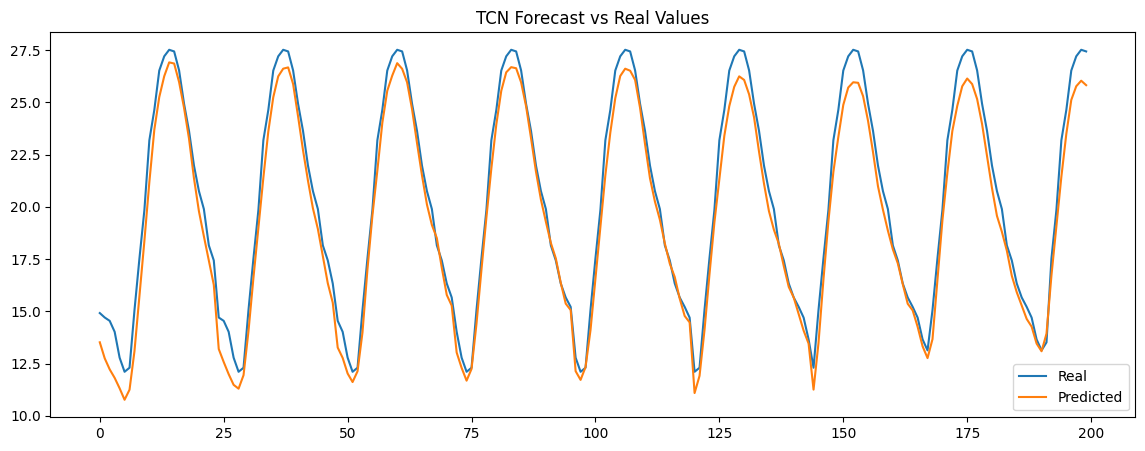

In [5]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14,5))
plt.plot(y_test_real[:200], label="Real")
plt.plot(y_pred_tcn_real[:200], label="Predicted")
plt.legend()
plt.title("TCN Forecast vs Real Values")
plt.show()


In [6]:
#TFT
from tensorflow.keras.callbacks import EarlyStopping
inputs = layers.Input(shape=input_shape)

# időbeli kódolás (LSTM)
x = layers.LSTM(64, return_sequences=True, dropout=0.2)(inputs)
x = layers.LSTM(64, return_sequences=True, dropout=0.2)(x)

# attention a teljes szekvenciára
attention = layers.MultiHeadAttention(num_heads=4, key_dim=32)
x_attn = attention(x, x)

x = layers.Concatenate()([x, x_attn])
x = layers.GlobalAveragePooling1D()(x)
x = layers.Dense(64, activation="relu")(x)
x = layers.Dropout(0.2)(x)
outputs = layers.Dense(output_horizon)(x)

tft_like_model = models.Model(inputs, outputs)
tft_like_model.compile(optimizer="adam", loss="mse", metrics=["mae"])


# early_stop = EarlyStopping(
#     monitor="val_loss",
#     patience=5,
#     restore_best_weights=True
# )

history_tft = tft_like_model.fit(
    X_train, y_train,
    validation_split=0.1,
    epochs=15,
    batch_size=64,
    # callbacks=[early_stop]
)



2026-02-13 15:20:28.116083: W external/local_xla/xla/tsl/framework/cpu_allocator_impl.cc:84] Allocation of 2281564320 exceeds 10% of free system memory.
2026-02-13 15:20:31.531223: W external/local_xla/xla/tsl/framework/cpu_allocator_impl.cc:84] Allocation of 2281564320 exceeds 10% of free system memory.


Epoch 1/15
10610/10610 ━━━━━━━━━━━━━━━━━━━━ 248s 23ms/step - loss: 0.0081 - mae: 0.0658 - val_loss: 0.0200 - val_mae: 0.1318
Epoch 2/15
10610/10610 ━━━━━━━━━━━━━━━━━━━━ 210s 20ms/step - loss: 0.0031 - mae: 0.0414 - val_loss: 0.0146 - val_mae: 0.1127
Epoch 3/15
10610/10610 ━━━━━━━━━━━━━━━━━━━━ 213s 20ms/step - loss: 0.0027 - mae: 0.0389 - val_loss: 0.0160 - val_mae: 0.1178
Epoch 4/15
10610/10610 ━━━━━━━━━━━━━━━━━━━━ 210s 20ms/step - loss: 0.0026 - mae: 0.0381 - val_loss: 0.0133 - val_mae: 0.1069
Epoch 5/15
10610/10610 ━━━━━━━━━━━━━━━━━━━━ 213s 20ms/step - loss: 0.0025 - mae: 0.0377 - val_loss: 0.0162 - val_mae: 0.1192
Epoch 6/15
10610/10610 ━━━━━━━━━━━━━━━━━━━━ 212s 20ms/step - loss: 0.0024 - mae: 0.0372 - val_loss: 0.0149 - val_mae: 0.1126
Epoch 7/15
10610/10610 ━━━━━━━━━━━━━━━━━━━━ 210s 20ms/step - loss: 0.0023 - mae: 0.0368 - val_loss: 0.0181 - val_mae: 0.1286
Epoch 8/15
10610/10610 ━━━━━━━━━━━━━━━━━━━━ 209s 20ms/step - loss: 0.0023 - mae: 0.0364 - val_loss: 0.0172 - val_mae: 0.1243


In [7]:
y_pred_tft = tft_like_model.predict(X_test)

# Flatten (multi-step → 1D)
y_pred_flat = y_pred_tft.reshape(-1, 1)
y_test_flat = y_test.reshape(-1, 1)

# Visszaskálázás (csak a target oszlopot)
y_pred_tft_real = scaler.inverse_transform(
    np.hstack([np.zeros((len(y_pred_flat), len(features))), y_pred_flat])
)[:, -1]

y_test_real = scaler.inverse_transform(
    np.hstack([np.zeros((len(y_test_flat), len(features))), y_test_flat])
)[:, -1]


6/6 ━━━━━━━━━━━━━━━━━━━━ 1s 66ms/step


In [8]:
mse_tft = mean_squared_error(y_test_real, y_pred_tft_real)
mae_tft = mean_absolute_error(y_test_real, y_pred_tft_real)
rmse_tft = np.sqrt(mse_tft)

print("TFT-like – MSE:", mse_tft)
print("TFT-like – MAE:", mae_tft)
print("TFT-like – RMSE:", rmse_tft)


TFT-like – MSE: 23.211897729174282
TFT-like – MAE: 4.550935622368047
TFT-like – RMSE: 4.817872738997397


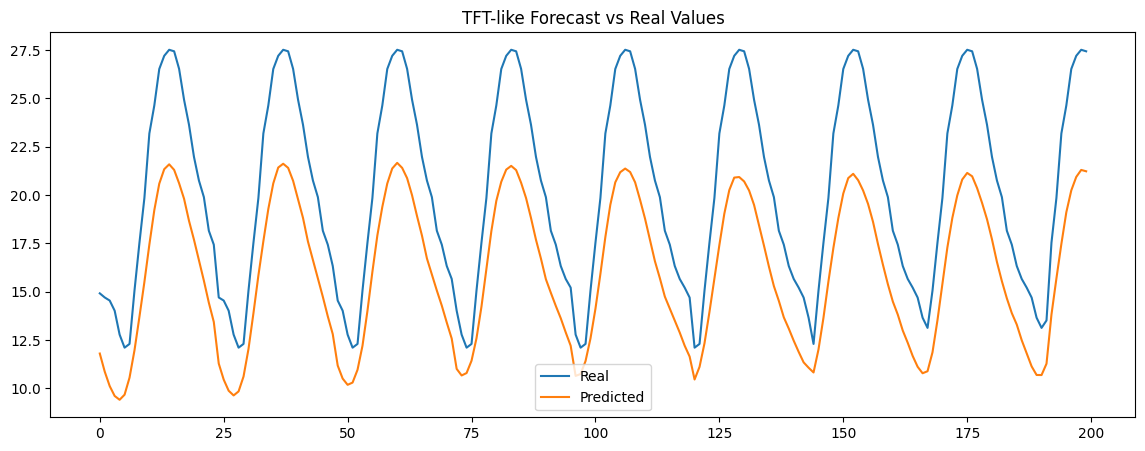

In [9]:

plt.figure(figsize=(14,5))
plt.plot(y_test_real[:200], label="Real")
plt.plot(y_pred_tft_real[:200], label="Predicted")
plt.legend()
plt.title("TFT-like Forecast vs Real Values")
plt.show()


In [10]:
#Autoformer
inputs = layers.Input(shape=input_shape)

# lineáris projekció
x = layers.Dense(64)(inputs)

# transformer blokkok
for _ in range(2):
    attn_out = layers.MultiHeadAttention(num_heads=4, key_dim=32)(x, x)
    x = layers.Add()([x, attn_out])
    x = layers.LayerNormalization()(x)
    ff = layers.Dense(128, activation="relu")(x)
    ff = layers.Dense(64)(ff)
    x = layers.Add()([x, ff])
    x = layers.LayerNormalization()(x)

x = layers.GlobalAveragePooling1D()(x)
x = layers.Dense(64, activation="relu")(x)
outputs = layers.Dense(output_horizon)(x)

autoformer_like_model = models.Model(inputs, outputs)
autoformer_like_model.compile(optimizer="adam", loss="mse", metrics=["mae"])

history_auto = autoformer_like_model.fit(
    X_train, y_train,
    validation_split=0.1,
    epochs=15,
    batch_size=64
)


2026-02-13 16:13:39.841481: W external/local_xla/xla/tsl/framework/cpu_allocator_impl.cc:84] Allocation of 2281564320 exceeds 10% of free system memory.


Epoch 1/15
10610/10610 ━━━━━━━━━━━━━━━━━━━━ 136s 12ms/step - loss: 0.0117 - mae: 0.0917 - val_loss: 0.0100 - val_mae: 0.0853
Epoch 2/15
10610/10610 ━━━━━━━━━━━━━━━━━━━━ 114s 11ms/step - loss: 0.0110 - mae: 0.0901 - val_loss: 0.0100 - val_mae: 0.0851
Epoch 3/15
10610/10610 ━━━━━━━━━━━━━━━━━━━━ 114s 11ms/step - loss: 0.0107 - mae: 0.0890 - val_loss: 0.0096 - val_mae: 0.0837
Epoch 4/15
10610/10610 ━━━━━━━━━━━━━━━━━━━━ 113s 11ms/step - loss: 0.0105 - mae: 0.0875 - val_loss: 0.0095 - val_mae: 0.0827
Epoch 5/15
10610/10610 ━━━━━━━━━━━━━━━━━━━━ 112s 11ms/step - loss: 0.0103 - mae: 0.0862 - val_loss: 0.0093 - val_mae: 0.0817
Epoch 6/15
10610/10610 ━━━━━━━━━━━━━━━━━━━━ 112s 11ms/step - loss: 0.0100 - mae: 0.0850 - val_loss: 0.0092 - val_mae: 0.0807
Epoch 7/15
10610/10610 ━━━━━━━━━━━━━━━━━━━━ 113s 11ms/step - loss: 0.0099 - mae: 0.0840 - val_loss: 0.0091 - val_mae: 0.0803
Epoch 8/15
10610/10610 ━━━━━━━━━━━━━━━━━━━━ 110s 10ms/step - loss: 0.0097 - mae: 0.0830 - val_loss: 0.0089 - val_mae: 0.0791


In [11]:
y_pred_auto = autoformer_like_model.predict(X_test)

# Flatten (multi-step → 1D)
y_pred_flat = y_pred_auto.reshape(-1, 1)
y_test_flat = y_test.reshape(-1, 1)

# Visszaskálázás (csak a target oszlopot)
y_pred_auto_real = scaler.inverse_transform(
    np.hstack([np.zeros((len(y_pred_flat), len(features))), y_pred_flat])
)[:, -1]

y_test_real = scaler.inverse_transform(
    np.hstack([np.zeros((len(y_test_flat), len(features))), y_test_flat])
)[:, -1]


6/6 ━━━━━━━━━━━━━━━━━━━━ 3s 267ms/step


In [12]:

mse_auto = mean_squared_error(y_test_real, y_pred_auto_real)
mae_auto = mean_absolute_error(y_test_real, y_pred_auto_real)
rmse_auto = np.sqrt(mse_auto)

print("Autoformer-like – MSE:", mse_auto)
print("Autoformer-like – MAE:", mae_auto)
print("Autoformer-like – RMSE:", rmse_auto)


Autoformer-like – MSE: 23.11036237374505
Autoformer-like – MAE: 3.9716326026578694
Autoformer-like – RMSE: 4.807323826594694


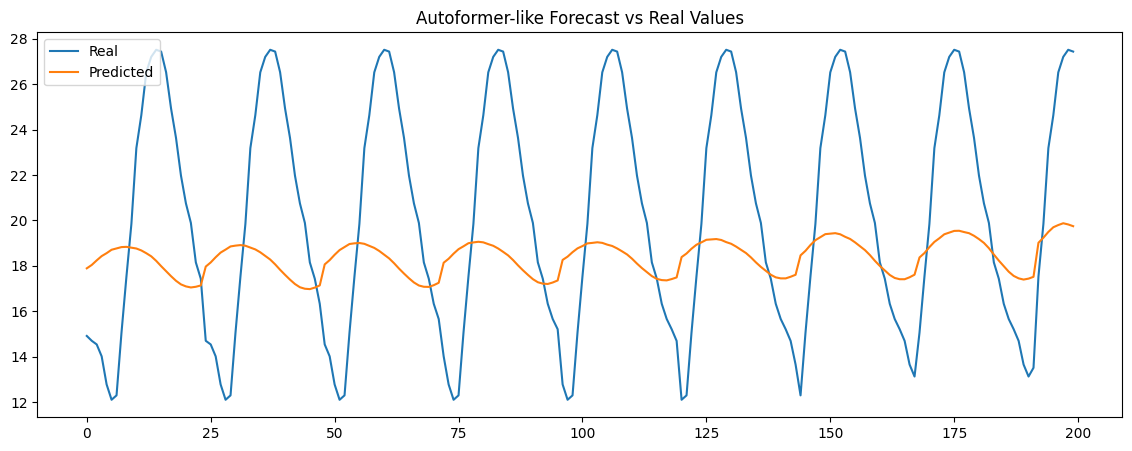

In [13]:

plt.figure(figsize=(14,5))
plt.plot(y_test_real[:200], label="Real")
plt.plot(y_pred_auto_real[:200], label="Predicted")
plt.legend()
plt.title("Autoformer-like Forecast vs Real Values")
plt.show()


In [14]:
#TimesNET
inputs = layers.Input(shape=input_shape)

x1 = layers.Conv1D(64, kernel_size=3, padding="causal", activation="relu")(inputs)
x2 = layers.Conv1D(64, kernel_size=5, padding="causal", activation="relu")(inputs)
x3 = layers.Conv1D(64, kernel_size=7, padding="causal", activation="relu")(inputs)

x = layers.Concatenate()([x1, x2, x3])
x = layers.GlobalAveragePooling1D()(x)
x = layers.Dense(64, activation="relu")(x)
outputs = layers.Dense(output_horizon)(x)

timesnet_like_model = models.Model(inputs, outputs)
timesnet_like_model.compile(optimizer="adam", loss="mse", metrics=["mae"])

history_times = timesnet_like_model.fit(
    X_train, y_train,
    validation_split=0.1,
    epochs=15,
    batch_size=64
)


Epoch 1/15
10610/10610 ━━━━━━━━━━━━━━━━━━━━ 43s 4ms/step - loss: 0.0050 - mae: 0.0531 - val_loss: 0.0026 - val_mae: 0.0391
Epoch 2/15
10610/10610 ━━━━━━━━━━━━━━━━━━━━ 38s 4ms/step - loss: 0.0025 - mae: 0.0387 - val_loss: 0.0025 - val_mae: 0.0382
Epoch 3/15
10610/10610 ━━━━━━━━━━━━━━━━━━━━ 38s 4ms/step - loss: 0.0022 - mae: 0.0361 - val_loss: 0.0020 - val_mae: 0.0344
Epoch 4/15
10610/10610 ━━━━━━━━━━━━━━━━━━━━ 38s 4ms/step - loss: 0.0020 - mae: 0.0345 - val_loss: 0.0020 - val_mae: 0.0338
Epoch 5/15
10610/10610 ━━━━━━━━━━━━━━━━━━━━ 37s 4ms/step - loss: 0.0019 - mae: 0.0334 - val_loss: 0.0019 - val_mae: 0.0329
Epoch 6/15
10610/10610 ━━━━━━━━━━━━━━━━━━━━ 37s 4ms/step - loss: 0.0018 - mae: 0.0326 - val_loss: 0.0017 - val_mae: 0.0313
Epoch 7/15
10610/10610 ━━━━━━━━━━━━━━━━━━━━ 37s 3ms/step - loss: 0.0017 - mae: 0.0319 - val_loss: 0.0017 - val_mae: 0.0317
Epoch 8/15
10610/10610 ━━━━━━━━━━━━━━━━━━━━ 37s 4ms/step - loss: 0.0017 - mae: 0.0313 - val_loss: 0.0017 - val_mae: 0.0316
Epoch 9/15
10610

In [15]:
y_pred_times = timesnet_like_model.predict(X_test)

# Flatten (multi-step → 1D)
y_pred_flat = y_pred_times.reshape(-1, 1)
y_test_flat = y_test.reshape(-1, 1)

# Visszaskálázás (csak a target oszlopot)
y_pred_times_real = scaler.inverse_transform(
    np.hstack([np.zeros((len(y_pred_flat), len(features))), y_pred_flat])
)[:, -1]

y_test_real = scaler.inverse_transform(
    np.hstack([np.zeros((len(y_test_flat), len(features))), y_test_flat])
)[:, -1]


6/6 ━━━━━━━━━━━━━━━━━━━━ 1s 121ms/step


In [16]:

mse_times = mean_squared_error(y_test_real, y_pred_times_real)
mae_times = mean_absolute_error(y_test_real, y_pred_times_real)
rmse_times = np.sqrt(mse_times)

print("TimesNet-like – MSE:", mse_times)
print("TimesNet-like – MAE:", mae_times)
print("TimesNet-like – RMSE:", rmse_times)


TimesNet-like – MSE: 2.260715255523029
TimesNet-like – MAE: 1.2016244669642633
TimesNet-like – RMSE: 1.503567509466412


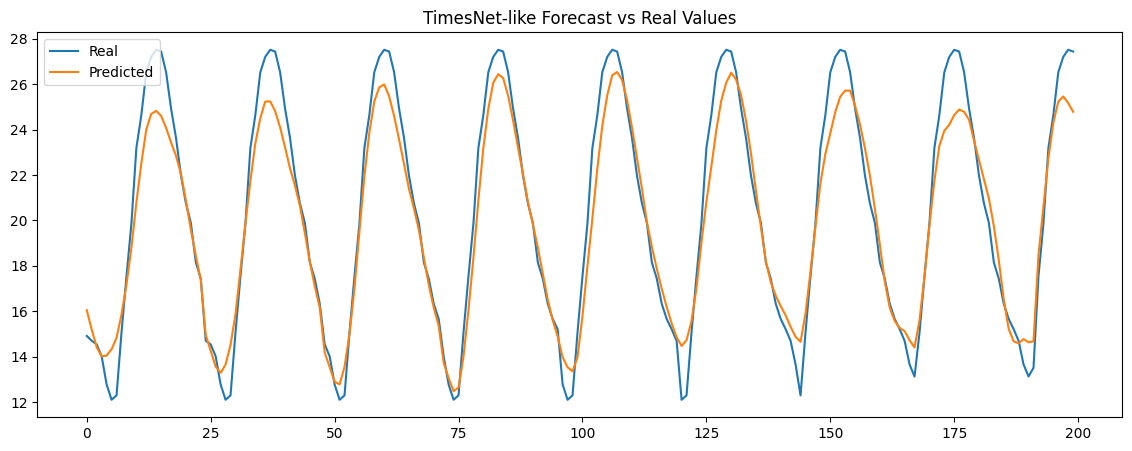

In [17]:

plt.figure(figsize=(14,5))
plt.plot(y_test_real[:200], label="Real")
plt.plot(y_pred_times_real[:200], label="Predicted")
plt.legend()
plt.title("TimesNet-like Forecast vs Real Values")
plt.show()


In [18]:
#Summary
from sklearn.metrics import mean_squared_error, mean_absolute_error

def evaluate_model(model, name):
    y_pred = model.predict(X_test)
    y_pred_flat = y_pred.reshape(-1, 1)
    y_test_flat = y_test.reshape(-1, 1)

    y_pred_real = scaler.inverse_transform(
        np.hstack([np.zeros((len(y_pred_flat), len(features))), y_pred_flat])
    )[:, -1]

    y_test_real = scaler.inverse_transform(
        np.hstack([np.zeros((len(y_test_flat), len(features))), y_test_flat])
    )[:, -1]

    mse = mean_squared_error(y_test_real, y_pred_real)
    mae = mean_absolute_error(y_test_real, y_pred_real)
    rmse = np.sqrt(mse)
    print(f"{name} – MSE: {mse:.4f}, MAE: {mae:.4f}, RMSE: {rmse:.4f}")
    return mse, mae, rmse

evaluate_model(tcn_model, "TCN")
evaluate_model(tft_like_model, "TFT-like")
evaluate_model(autoformer_like_model, "Autoformer-like")
evaluate_model(timesnet_like_model, "TimesNet-like")


6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step 
TCN – MSE: 1.2886, MAE: 0.8993, RMSE: 1.1352
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step
TFT-like – MSE: 23.2119, MAE: 4.5509, RMSE: 4.8179
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step 
Autoformer-like – MSE: 23.1104, MAE: 3.9716, RMSE: 4.8073
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step 
TimesNet-like – MSE: 2.2607, MAE: 1.2016, RMSE: 1.5036


(2.260715255523029, 1.2016244669642633, np.float64(1.503567509466412))

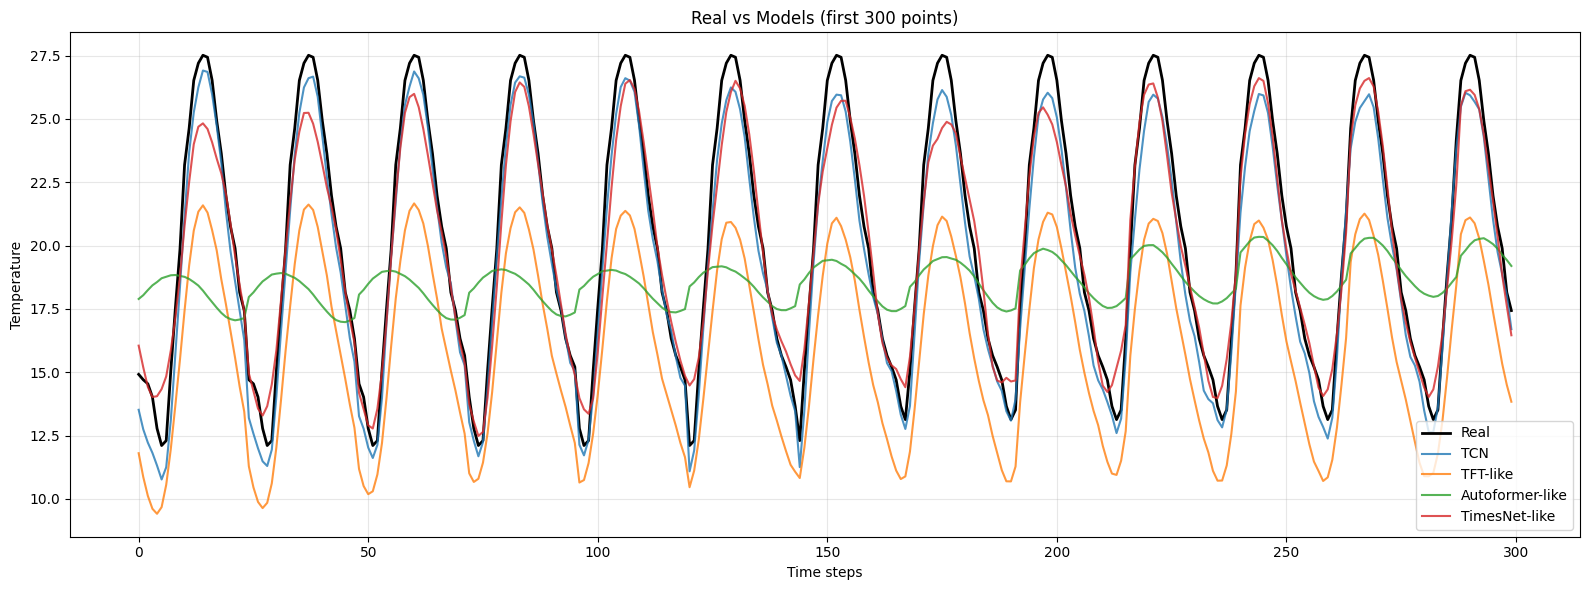

In [19]:

# hány pontot nézzünk meg a grafikonon
N = 300  # nyugodtan állítsd, pl. 200, 500 stb.

plt.figure(figsize=(16, 6))

plt.plot(y_test_real[:N], label="Real", color="black", linewidth=2)

plt.plot(y_pred_tcn_real[:N],   label="TCN",           alpha=0.8)
plt.plot(y_pred_tft_real[:N],   label="TFT-like",      alpha=0.8)
plt.plot(y_pred_auto_real[:N],  label="Autoformer-like", alpha=0.8)
plt.plot(y_pred_times_real[:N], label="TimesNet-like", alpha=0.8)

plt.title(f"Real vs Models (first {N} points)")
plt.xlabel("Time steps")
plt.ylabel("Temperature")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


In [20]:
#Modellek mentése
tcn_model.save("models2/tcn_model.keras")
tft_like_model.save("models2/tft_model.keras")
autoformer_like_model.save("models2/autoformer_model.keras")
timesnet_like_model.save("models2/timesnet_model.keras")

#Visszatöltés
#from tensorflow.keras.models import load_model

#tcn_model = load_model("models/tcn_model")
#timesnet_model = load_model("models/timesnet_model")

#Scaler mentése!
import joblib
joblib.dump(scaler, "models2/scaler.pkl")

#Visszatöltés:
#scaler = joblib.load("models/scaler.pkl")

#Features mentése
import json
json.dump(features, open("models2/features.json", "w"))

#Visszatöltés
#features = json.load(open("models/features.json"))

#Windows paraméterek:
json.dump(
    {"input_window": input_window, "output_horizon": output_horizon},
    open("models2/window_params.json", "w")
)

#Visszatöltés
#params = json.load(open("models/window_params.json"))
#input_window = params["input_window"]
#output_horizon = params["output_horizon"]

